# HyDE

**이 노트북에서 할 일**

1. Ch 12에서 쓰던 문서 열두 건과 질문 여덟 개를 그대로 읽습니다.
2. 일상에서 말하듯 짧게 적은 원 질문을 하나 정합니다.
3. 그 질문을 한 번만 검색해 정답 문서의 자리를 셉니다.
4. 같은 질문에 답할 법한 안내문을 모델에게 지어 받습니다.
5. 질문 대신 그 글을 검색에 넣어 정답 문서의 자리를 다시 셉니다.
6. 질문만 바꾸어 같은 일을 다시 하고 두 결과를 견줍니다.

**준비물** — 이 절은 프로젝트 맨 위 폴더의 `.env`에 적어 둔 `OPENAI_API_KEY`를 씁니다.
서비스 요청은 일곱 번입니다(임베딩 다섯 번과 답 모델 두 번).
예상 비용은 미화 0.01달러 아래입니다.
읽어 오는 파일은 이 챕터 폴더의 문서 파일과 질문 파일 둘이고 새로 쓰는 파일은 없습니다.
실행 시간은 2분 안팎이고 첫 셀의 설치가 가장 오래 걸립니다.

**기준 버전** — 첫 셀에서 LangChain 1.4.0과 langchain-openai 1.6.1을 설치합니다.
키를 읽는 python-dotenv 1.2.3과 도구 파일이 쓰는 numpy 2.5.3도 함께 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 3절부터 7절까지 읽습니다.
Ch 12 검색 부품을 준비하고 짧게 적은 원 질문을 고르는 자리입니다.
8절과 9절은 가상 문서를 지어 그 글로 검색하는 자리입니다.
10절과 11절은 질문을 바꾸어 같은 일을 한 번 더 하고 네 실행을 표로 보는 자리입니다.

실습 폴더 `labs/part4/ch14-rag-patterns`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

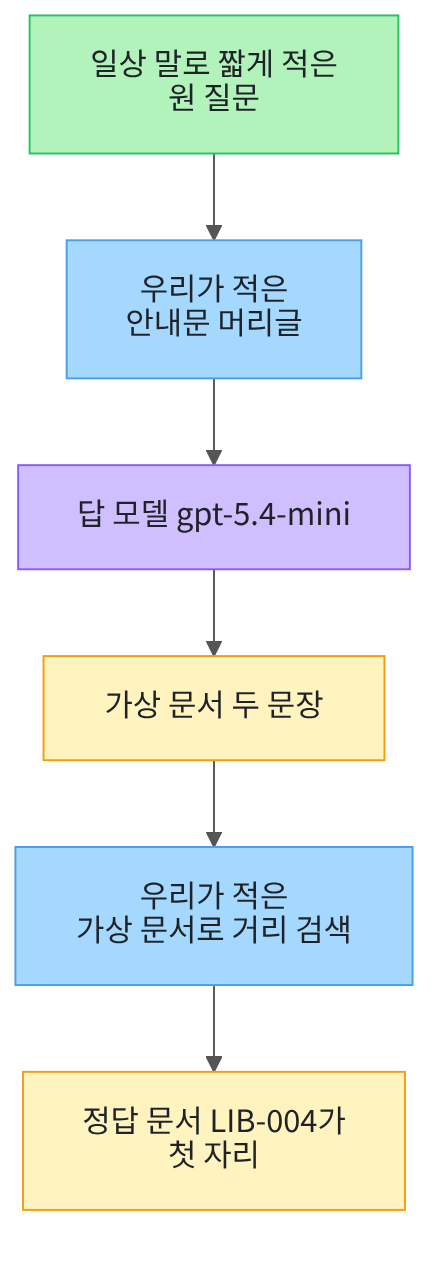

위에서 아래로 읽습니다.
맨 위 초록 상자가 사람이 적은 질문입니다.
가운데 파란 상자 둘이 우리가 적은 글과 처리이고 보라 상자가 모델입니다.
노란 상자 둘이 출력으로 확인한 값입니다.

## 1. 준비

첫 셀은 패키지 네 개를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.1" "python-dotenv==1.2.3" "numpy==2.5.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))
print("numpy:", version("numpy"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-openai: 1.6.1
python-dotenv: 1.2.3
numpy: 2.5.3


**결과 읽기** — 설치가 끝나면 판 번호 네 줄이 보입니다.
마지막 줄 `numpy: 2.5.3`은 도구 파일이 벡터 계산에 쓰는 패키지입니다.
이 노트북의 출력은 2026-09-21에 이 판으로 실행한 결과입니다.

다음 셀은 이름 네 개를 불러오고 도구 파일에서 함수 여섯 개를 가져옵니다.
앞의 둘은 자료 읽기와 폴더 확인에 씁니다.
뒤의 둘은 Ch 9~13에서 쓴 임베딩과 답 모델 이름입니다.

앞에서 배운 함수는 `rag_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.

이 노트북은 Ch 12 01절 `rank_by_distance()`와 05절 `print_ranked()`를 가져옵니다.
Ch 11 01절 `unique_doc_ids()`·`find_gold_rank()`도 가져옵니다.
02절에서 만든 `split_lines()`와 `search_ids()`도 함께 가져옵니다.
인자 모양은 5절에서 설명합니다.

In [2]:
# 자료 읽기·폴더 확인과 임베딩·답 모델 이름을 불러옵니다
import json
import os

from langchain_openai import OpenAIEmbeddings
from langchain.chat_models import init_chat_model
# Ch 12 01·05절·Ch 11 01절 함수와 02절 함수를 도구 파일에서 가져옵니다
from rag_tools import find_gold_rank, print_ranked, rank_by_distance, search_ids
from rag_tools import split_lines, unique_doc_ids

print("불러온 이름:", "json", "os", "OpenAIEmbeddings", "init_chat_model")

불러온 이름: json os OpenAIEmbeddings init_chat_model


**결과 읽기** — 출력 줄에 불러온 이름 네 개가 보입니다.
이름 `OpenAIEmbeddings`와 `init_chat_model`은 04절에서 쓴 것과 같습니다.
도구 파일에서 가져온 함수 여섯 개는 출력하지 않습니다.

## 2. 키와 모델 준비

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어 매번 비슷한 답을 고르게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-21에 이 모델로 실행한 결과입니다.

## 3. 문서와 질문 읽기

이 절은 01~04절과 같은 문서 파일과 질문 파일을 읽습니다.
두 파일은 Ch 12 core 벌 파일과 바이트가 같은 사본입니다.
먼저 노트북을 연 자리에서 프로젝트 맨 위를 찾습니다.

In [5]:
# 노트북을 어느 폴더에서 열어도 프로젝트 맨 위를 찾게 후보 세 개를 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part4/ch14-rag-patterns/data"):
        root_path = candidate
        break
print("고른 자리:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

고른 자리: .


**결과 읽기** — 출력 줄 `고른 자리` 뒤에 점 하나나 위로 올라가는 표시가 보입니다.
Ch 10~13과 01~04절에서 쓴 방법과 같습니다.
후보 셋 가운데 이 챕터 자료 폴더가 있는 자리를 고릅니다.

다음 셀은 문서 파일과 질문 파일을 읽습니다.

In [6]:
# 이 챕터 폴더의 문서 파일과 질문 파일을 읽습니다(읽기만 하고 고치지 않습니다)
data_path = root_path + "/labs/part4/ch14-rag-patterns/data"
with open(data_path + "/documents.json", encoding="utf-8") as file:
    docs = json.loads(file.read())
with open(data_path + "/queries.json", encoding="utf-8") as file:
    queries = json.loads(file.read())
print("문서 수:", len(docs))
print("질문 수:", len(queries))

문서 수: 12
질문 수: 8


**결과 읽기** — 출력 줄 `문서 수: 12`와 `질문 수: 8`이 Ch 12 core 벌 그대로입니다.
문서는 도서관 안내 열두 건입니다.

질문 번호는 C01부터 C08까지이고 질문 파일에 적혀 있습니다.
이 절이 쓸 질문은 그 여덟 개에 없어 아래에서 손으로 적습니다.

## 4. 이 절에서 쓸 값 정하기

Ch 12와 01~04절에서 정한 값을 그대로 다시 적습니다.
지어낼 가상 문서의 문장 수도 여기서 못 박아 둡니다.

In [7]:
# Ch 12에서 쓴 값을 그대로 다시 정하고 지어낼 가상 문서의 문장 수도 못 박습니다
top_three = 3
top_all = 12
doc_sentences = 2
print("나란히 볼 상위 문서 수:", top_three)
print("자리를 셀 때 재는 문서 수:", top_all)
print("가상 문서의 문장 수:", doc_sentences)

나란히 볼 상위 문서 수: 3
자리를 셀 때 재는 문서 수: 12
가상 문서의 문장 수: 2


**결과 읽기** — 출력 줄 `나란히 볼 상위 문서 수: 3`은 표로 볼 자리 수입니다.
출력 줄 `자리를 셀 때 재는 문서 수: 12`는 정답 문서의 자리를 끝까지 세려고 둔 값입니다.
출력 줄 `가상 문서의 문장 수: 2`는 모델에게 받을 문장 수입니다.

04절은 이 자리에 만들 넓힌 질문 개수 하나를 두었습니다.
이 절은 질문이 아니라 두 문장짜리 글을 받으므로 값의 뜻이 다릅니다.

## 5. 앞 절 부품 준비

다음 셀은 01~04절과 같은 방법으로 문서 열두 건의 제목과 본문을 이어 붙입니다.
읽지 말고 실행만 하고 넘어가도 됩니다.
함수는 준비 셀에서 도구 파일로 가져왔습니다.
02절 `search_ids()`의 도구 파일 판은 임베딩 모델과 질문과 문서 벡터 목록과 문서 ID 목록과 개수를 받습니다.

In [8]:
# 문서 12개의 제목과 본문을 이어 붙이고 문서 ID 목록도 만듭니다(Ch 12와 같은 제목 + 본문 모양)
doc_texts = []
doc_ids = []
for doc in docs:
    doc_texts.append(doc["title"] + " " + doc["text"])
    doc_ids.append(doc["doc_id"])
print("이어 붙인 글 수:", len(doc_texts))
print("첫 문서 글:", doc_texts[0])
print("문서 ID 목록:")
print(doc_ids)

이어 붙인 글 수: 12
첫 문서 글: 도서 대출 기간 일반 도서는 14일 동안 대출할 수 있습니다. 예약자가 없으면 한 번 연장할 수 있습니다.
문서 ID 목록:
['LIB-001', 'LIB-002', 'LIB-003', 'LIB-004', 'FAC-001', 'FAC-002', 'FAC-003', 'FAC-004', 'ACC-001', 'ACC-002', 'ACC-003', 'ACC-004']


준비 셀 하나를 지났습니다.
02·03절이 쓴 순위 합치기 함수는 04절에 이어 이 절에서도 가져오지 않았습니다.
이 절도 목록 여러 개를 하나로 합치지 않기 때문입니다.

## 6. 문서를 벡터로 바꾸기

다음 셀은 문서 열두 건을 벡터로 바꿉니다.
이 절에서 서비스에 보내는 첫 요청입니다.

In [9]:
# Ch 12와 같은 모델로 문서 12개를 벡터로 바꿉니다(임베딩 요청 1번)
embedding_model_name = "text-embedding-3-small"
vector_dimensions = 256
embedding_model = OpenAIEmbeddings(model=embedding_model_name, dimensions=vector_dimensions)
doc_vectors = embedding_model.embed_documents(doc_texts)
print("임베딩 모델 이름:", embedding_model.model)
print("벡터의 숫자 개수 설정:", embedding_model.dimensions)
print("문서 벡터 수:", len(doc_vectors))

임베딩 모델 이름: text-embedding-3-small
벡터의 숫자 개수 설정: 256
문서 벡터 수: 12


**결과 읽기** — 출력 줄 `임베딩 모델 이름: text-embedding-3-small`은 04절과 같은 모델입니다.
출력 줄 `벡터의 숫자 개수 설정: 256`도 Ch 10~13과 같은 값입니다.
출력 줄 `문서 벡터 수: 12`로 문서마다 벡터 하나를 받았습니다.
벡터 안의 숫자는 호출마다 아주 조금씩 달라져 소수 자리까지 같다고 보지 않습니다.

## 7. 짧게 적은 원 질문

자료의 문서는 안내문 문장으로 적혀 있습니다.
사람이 묻는 말은 그보다 짧고 쓰는 낱말도 다릅니다.
그런 질문을 하나 적고 판단에 쓸 정답 문서도 함께 정합니다.

In [10]:
# 일상에서 말하듯 짧게 적은 원 질문과 그 질문의 정답 문서를 정합니다
base_question = "폰으로 보는 건 며칠이에요?"
gold_doc_id = "LIB-004"
gold_title = ""
for doc in docs:
    if doc["doc_id"] == gold_doc_id:
        gold_title = doc["title"]
print("원 질문:", base_question)
print("이 질문의 정답 문서 ID:", gold_doc_id)
print("그 문서의 제목:", gold_title)

원 질문: 폰으로 보는 건 며칠이에요?
이 질문의 정답 문서 ID: LIB-004
그 문서의 제목: 전자책 이용


**결과 읽기** — 출력 줄 `원 질문` 뒤에 아홉 글자짜리 짧은 물음이 있습니다.
출력 줄 `이 질문의 정답 문서 ID: LIB-004`는 전자책 이용을 적은 문서입니다.
출력 줄 `그 문서의 제목: 전자책 이용`으로 제목을 확인했습니다.

실행 전에 예상해 봅니다.
질문에 전자책이라는 말이 없으니 다른 문서가 먼저 걸릴 것입니다.

In [11]:
# 원 질문을 한 번만 검색해 순위 표와 정답 문서의 자리를 봅니다(임베딩 요청 1번)
base_vector = embedding_model.embed_query(base_question)
base_hits = rank_by_distance(base_vector, doc_vectors, doc_ids, top_all)
base_ids = unique_doc_ids(base_hits)
base_place = find_gold_rank(base_ids, [gold_doc_id])
print_ranked(base_hits[:top_three], "거리")
print("원 질문으로 검색했을 때 정답 문서의 자리:", base_place)

순위 | 문서 ID | 거리
1 | FAC-003 | 0.69
2 | ACC-001 | 0.73
3 | FAC-002 | 0.75
원 질문으로 검색했을 때 정답 문서의 자리: 4


**결과 읽기** — 순위 표의 차례는 `FAC-003`과 `ACC-001`과 `FAC-002`입니다.
세 문서 모두 이 물음의 정답 문서가 아닙니다.
출력 줄 `원 질문으로 검색했을 때 정답 문서의 자리: 4`로 정답 문서는 넷째였습니다.

거리 값은 셋째 자리 아래가 호출마다 달라져 본문과 그림에 넣지 않았습니다.
짧은 물음에는 자료가 쓰는 낱말이 거의 들어 있지 않습니다.

## 8. 답처럼 보이는 글 지어내기

01절부터 04절까지는 질문을 질문으로 바꿔 검색했습니다.
이 절은 질문 대신 답처럼 보이는 글을 지어 검색에 넣습니다.
머리글에 문장 수와 모양을 적고 지어낸 숫자를 넣지 말라는 줄도 함께 넣습니다.

In [12]:
# 머리글 네 줄과 원 질문을 한 글로 이어 붙입니다
def build_hyde_prompt(question):
    hyde_head = "아래 질문에 답할 법한 도서관 안내문을 지어 쓰세요.\n"
    hyde_head = hyde_head + "물음표로 끝나는 질문이 아니라 안내문 문장으로 " + str(doc_sentences) + "문장 적으세요.\n"
    hyde_head = hyde_head + "지어낸 숫자는 넣지 말고 무엇을 어디에서 하는지만 적으세요.\n"
    hyde_head = hyde_head + "번호나 따옴표를 붙이지 마세요.\n\n"
    prompt_text = hyde_head + "질문: " + question
    return prompt_text

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `build_hyde_prompt`는 머리글 네 줄을 이어 붙인 뒤 원 질문을 답니다.
머리글의 문장 수 자리에는 앞에서 정한 값 `doc_sentences`가 들어갑니다.
숫자를 넣지 말라고 적은 까닭은 지어낸 숫자를 답에 쓸 수 없기 때문입니다.

다음 셀은 그 글을 만들어 모델에 넣습니다.

In [13]:
# 만든 글을 모델에 넣어 답처럼 보이는 안내문을 받습니다(모델 요청 1번)
hyde_prompt = build_hyde_prompt(base_question)
print("모델에 넣을 글:")
print(hyde_prompt)
hyde_reply = model.invoke(hyde_prompt)
hyde_text = hyde_reply.text.strip()
print("모델이 쓴 글:")
print(hyde_text)

모델에 넣을 글:
아래 질문에 답할 법한 도서관 안내문을 지어 쓰세요.
물음표로 끝나는 질문이 아니라 안내문 문장으로 2문장 적으세요.
지어낸 숫자는 넣지 말고 무엇을 어디에서 하는지만 적으세요.
번호나 따옴표를 붙이지 마세요.

질문: 폰으로 보는 건 며칠이에요?


모델이 쓴 글:
휴대폰으로 보는 전자책 이용 기간은 도서관 홈페이지의 전자자료 안내에서 확인하실 수 있습니다.  
전자책 대출과 반납은 모바일 앱에서 이용하실 수 있습니다.


**결과 읽기** — 라벨 줄 `모델에 넣을 글:` 아래에 머리글 네 줄과 원 질문이 있습니다.
라벨 줄 `모델이 쓴 글:` 아래에는 물음표가 없는 안내문이 있습니다.
04절까지는 이 자리에 늘 질문이 나왔습니다.

이 글은 자료에서 확인한 사실이 아닙니다.
문장은 실행마다 달라질 수 있어 이 값에 `assert`를 걸지 않았습니다.

In [14]:
# 줄 목록을 사이에 빈칸 하나를 두고 한 글로 이어 붙입니다
def join_lines(lines):
    joined_text = ""
    for line in lines:
        if joined_text == "":
            joined_text = line
        else:
            joined_text = joined_text + " " + line
    return joined_text

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `join_lines`는 줄 목록을 받아 사이에 빈칸 하나를 두고 이어 붙입니다.
두 문장이 한 줄로 올 때도 있고 두 줄로 나뉘어 올 때도 있습니다.
앞 줄만 쓰면 둘째 문장이 사라지므로 모두 이어 붙입니다.

다음 셀은 빈 줄을 뺀 뒤 그 함수로 가상 문서를 만듭니다.

In [15]:
# 모델이 보낸 글에서 빈 줄을 빼고 줄을 이어 붙여 가상 문서 한 글로 만듭니다
hyde_lines = split_lines(hyde_text)
hyde_doc = join_lines(hyde_lines)
print("모델이 보낸 줄 수:", len(hyde_lines))
print("가상 문서:")
print(hyde_doc)

모델이 보낸 줄 수: 2
가상 문서:
휴대폰으로 보는 전자책 이용 기간은 도서관 홈페이지의 전자자료 안내에서 확인하실 수 있습니다. 전자책 대출과 반납은 모바일 앱에서 이용하실 수 있습니다.


**결과 읽기** — 라벨 줄 `가상 문서:` 아래에 검색에 넣을 글 한 덩이가 있습니다.
출력 줄 `모델이 보낸 줄 수` 뒤의 수는 하나일 때도 둘일 때도 있습니다.
어느 쪽이든 이어 붙인 뒤 글은 하나입니다.

## 9. 가상 문서로 검색하기

이번에는 질문이 아니라 방금 지은 글을 검색에 넣습니다.
글의 길이와 문체가 자료의 문서와 더 가깝습니다.

In [16]:
# 질문 대신 가상 문서를 검색에 넣어 순위 표와 정답 문서의 자리를 봅니다(임베딩 요청 1번)
hyde_vector = embedding_model.embed_query(hyde_doc)
hyde_hits = rank_by_distance(hyde_vector, doc_vectors, doc_ids, top_all)
hyde_ids = unique_doc_ids(hyde_hits)
hyde_place = find_gold_rank(hyde_ids, [gold_doc_id])
print_ranked(hyde_hits[:top_three], "거리")
print("가상 문서로 검색했을 때 정답 문서의 자리:", hyde_place)

순위 | 문서 ID | 거리
1 | LIB-004 | 0.22
2 | ACC-002 | 0.42
3 | LIB-001 | 0.49
가상 문서로 검색했을 때 정답 문서의 자리: 1


**결과 읽기** — 순위 표의 첫 자리는 `LIB-004`입니다.
출력 줄 `가상 문서로 검색했을 때 정답 문서의 자리: 1`로 정답 문서가 맨 앞에 왔습니다.
같은 문서가 원 질문에서는 넷째 자리였습니다.

가상 문서에는 전자책과 이용 기간 같은 말이 들어 있습니다.
그래서 전자책 이용을 적은 문서와 가까워졌습니다.
순위 표의 거리 값은 새 커널로 다시 실행하면 달라집니다.
모델이 쓴 문장이 바뀌면 거리도 함께 바뀌기 때문입니다.

In [17]:
# 두 검색의 첫 자리 문서를 모으고 겹치는 문서를 빼 근거 문서 목록을 만듭니다
top_hits = []
top_hits.append({"doc_id": base_ids[0]})
top_hits.append({"doc_id": hyde_ids[0]})
evidence_ids = unique_doc_ids(top_hits)
print("원 질문 첫 자리 문서:", base_ids[0])
print("가상 문서 첫 자리 문서:", hyde_ids[0])
print("근거 문서 목록:", evidence_ids)

원 질문 첫 자리 문서: FAC-003
가상 문서 첫 자리 문서: LIB-004
근거 문서 목록: ['FAC-003', 'LIB-004']


**결과 읽기** — 출력 줄 `근거 문서 목록: ['FAC-003', 'LIB-004']`가 이 절이 얻으려던 값입니다.
앞의 문서는 원 질문이 찾은 문서이고 정답 문서가 아닙니다.
뒤의 문서는 가상 문서가 찾은 정답 문서입니다.

목록에 담긴 것은 자료에 있는 실제 문서의 ID입니다.
모델이 지어낸 글은 이 목록에 들어가지 않습니다.

## 10. 값 바꿔 보기 · 여러 문서에 걸치는 질문

바꿀 값은 검색에 넣을 원 질문 하나입니다.
머리글도 문장 수도 그대로 두고 질문만 바꿉니다.
정답 문서도 앞과 같은 문서로 둡니다.
실행 전에 예상해 봅니다.
권수를 묻는 말은 일반 도서 쪽에도 걸려 다른 문서가 앞설 것입니다.

In [18]:
# 바꿀 값은 검색에 넣을 원 질문 하나이고 정답 문서는 앞과 같은 문서로 둡니다(임베딩 요청 1번)
second_question = "한 번에 몇 권까지 되나요?"
second_ids = search_ids(embedding_model, second_question, doc_vectors, doc_ids, top_all)
second_place = find_gold_rank(second_ids, [gold_doc_id])
print("바꾼 질문:", second_question)
print("정답 문서는 앞과 같은 ID:", gold_doc_id)
print("바꾼 질문으로 한 번 검색했을 때 정답 문서의 자리:", second_place)

바꾼 질문: 한 번에 몇 권까지 되나요?
정답 문서는 앞과 같은 ID: LIB-004
바꾼 질문으로 한 번 검색했을 때 정답 문서의 자리: 3


**결과 읽기** — 출력 줄 `바꾼 질문` 뒤에 권수를 묻는 짧은 물음이 있습니다.
출력 줄 `정답 문서는 앞과 같은 ID: LIB-004`로 좇는 문서는 그대로입니다.
출력 줄 `바꾼 질문으로 한 번 검색했을 때 정답 문서의 자리: 3`으로 셋째였습니다.

다음 셀은 같은 머리글로 이 질문의 가상 문서도 지어 봅니다.

In [19]:
# 같은 머리글로 바꾼 질문의 가상 문서도 지어 봅니다(모델 요청 1번)
second_prompt = build_hyde_prompt(second_question)
second_reply = model.invoke(second_prompt)
second_lines = split_lines(second_reply.text.strip())
second_doc = join_lines(second_lines)
print("모델이 보낸 줄 수:", len(second_lines))
print("가상 문서:")
print(second_doc)

모델이 보낸 줄 수: 1
가상 문서:
대출 가능한 책의 수는 안내 데스크에서 확인하실 수 있습니다. 책을 빌리거나 반납하는 일은 대출 반납 창구에서 하실 수 있습니다.


**결과 읽기** — 라벨 줄 `가상 문서:` 아래에 모델이 지은 안내문이 있습니다.
이번 실행에서 이 글에는 전자책이라는 말이 없고 대출과 반납만 적혀 있습니다.
질문에 전자책이라는 말이 없어 모델이 일반 안내를 적었습니다.

다음 셀은 그 글로 같은 방법으로 검색합니다.

In [20]:
# 바꾼 질문의 가상 문서로 검색해 같은 방법으로 근거 문서 목록을 만듭니다(임베딩 요청 1번)
second_doc_ids = search_ids(embedding_model, second_doc, doc_vectors, doc_ids, top_all)
second_doc_place = find_gold_rank(second_doc_ids, [gold_doc_id])
second_hits = []
second_hits.append({"doc_id": second_ids[0]})
second_hits.append({"doc_id": second_doc_ids[0]})
second_evidence = unique_doc_ids(second_hits)
print("가상 문서 첫 자리 문서:", second_doc_ids[0])
print("가상 문서로 검색했을 때 정답 문서의 자리:", second_doc_place)
print("근거 문서 목록:", second_evidence)

가상 문서 첫 자리 문서: LIB-001
가상 문서로 검색했을 때 정답 문서의 자리: 4
근거 문서 목록: ['LIB-001']


**결과 읽기** — 출력 줄 `가상 문서 첫 자리 문서: LIB-001`은 정답 문서가 아닙니다.
출력 줄 `근거 문서 목록: ['LIB-001']`로 근거 문서가 하나입니다.
두 검색이 같은 문서를 첫 자리에 두어 목록에 하나만 남았습니다.

출력 줄 `가상 문서로 검색했을 때 정답 문서의 자리` 뒤의 수는 실행마다 달라집니다.
두 실행에서 모두 앞 세 자리 밖이었습니다.
한 번 검색에서는 셋째 자리였으므로 가상 문서가 정답 문서를 뒤로 밀었습니다.
지어낸 글이 다른 문서 쪽으로 기울면 이런 일이 생깁니다.

## 11. 네 실행을 기록 한 줄씩으로

실행 하나를 기록 한 줄로 만들어 담아 둡니다.
Ch 9~13과 01·02·04절에서 쓴 기록 한 줄과 같은 모양입니다.
칸 이름 하나만 「검색에 넣은 글」로 바꿨습니다.
이 절은 질문이 아닌 글도 검색에 넣기 때문입니다.

In [21]:
# 실행 한 번을 기록 한 줄로 만듭니다
def run_row(run_name, search_text, found_ids, place):
    row = {"실행": run_name}
    row["검색에 넣은 글"] = search_text
    row["첫 자리 문서"] = found_ids[0]
    row["정답 자리"] = place
    return row

**결과 읽기** — 정의 셀이라 출력이 없습니다.
담는 칸은 실행 이름과 검색에 넣은 글과 첫 자리 문서와 정답 자리 넷입니다.
이 절이 견주는 값이 그 넷이기 때문입니다.

다음 셀은 네 실행의 기록을 표로 출력합니다.

In [22]:
# 네 실행의 기록을 담아 라벨 줄 아래에 한 줄씩 출력합니다
run_rows = []
run_rows.append(run_row("원 질문 한 번 검색", base_question, base_ids, base_place))
run_rows.append(run_row("가상 문서로 검색", hyde_doc, hyde_ids, hyde_place))
run_rows.append(run_row("바꾼 질문 한 번 검색", second_question, second_ids, second_place))
run_rows.append(run_row("바꾼 질문의 가상 문서", second_doc, second_doc_ids, second_doc_place))
print("실행 | 첫 자리 문서 | 정답 자리")
for row in run_rows:
    print(row["실행"], "|", row["첫 자리 문서"], "|", row["정답 자리"])
    print("  검색에 넣은 글:", row["검색에 넣은 글"])

실행 | 첫 자리 문서 | 정답 자리
원 질문 한 번 검색 | FAC-003 | 4
  검색에 넣은 글: 폰으로 보는 건 며칠이에요?
가상 문서로 검색 | LIB-004 | 1
  검색에 넣은 글: 휴대폰으로 보는 전자책 이용 기간은 도서관 홈페이지의 전자자료 안내에서 확인하실 수 있습니다. 전자책 대출과 반납은 모바일 앱에서 이용하실 수 있습니다.
바꾼 질문 한 번 검색 | LIB-001 | 3
  검색에 넣은 글: 한 번에 몇 권까지 되나요?
바꾼 질문의 가상 문서 | LIB-001 | 4
  검색에 넣은 글: 대출 가능한 책의 수는 안내 데스크에서 확인하실 수 있습니다. 책을 빌리거나 반납하는 일은 대출 반납 창구에서 하실 수 있습니다.


**결과 읽기** — 라벨 줄 `실행 | 첫 자리 문서 | 정답 자리` 아래에 실행마다 두 줄씩 나옵니다.
첫 줄은 `원 질문 한 번 검색 | FAC-003 | 4`입니다.
둘째 실행은 `가상 문서로 검색 | LIB-004 | 1`입니다.
셋째 실행은 `바꾼 질문 한 번 검색 | LIB-001 | 3`입니다.

넷째 실행의 정답 자리는 새 커널로 다시 실행하면 달라집니다.
두 실행에서 모두 앞 세 자리 밖이었습니다.

## 정리

1. 짧게 적은 원 질문으로 한 번 검색하니 정답 문서가 넷째 자리였습니다.
2. 같은 질문으로 가상 문서를 지어 검색하니 정답 문서가 첫 자리로 왔습니다.
3. 두 검색의 첫 자리 문서를 모으니 근거 문서 목록에 문서 둘이 담겼습니다.
4. 질문을 바꾼 자리에서는 가상 문서가 정답 문서를 앞 세 자리 밖으로 밀었습니다.

06절에서는 첫 검색의 첫 자리 거리가 기준값보다 클 때만 한 번 더 검색합니다.
이 절은 검색에 넣을 글을 바꿨고 06절은 검색 뒤 결과를 보고 다시 검색할지 정합니다.